<a href="https://colab.research.google.com/github/wdestryker/MV2627_Exercises/blob/main/Project2627/project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<font color ='Navy'><center> __BruFace__ </center></font>
<br> MA1 Mechanical Engineering <br>  __Mechanical vibrations__ <br>
**Academic Year 2026-2027**
***
<font color='Navy'><h1><center>Project: 4 DOFs Model of a Car Under Road Excitation </center></h1></font>
- Arnaud Deraemaeker ([Arnaud.Deraemaeker@ulb.be](mailto:Arnaud.Deraemaeker@ulb.be))  
- Wout Weijtjens ([Wout.Weijtjens@vub.be](mailto:Wout.Weijtjens@vub.be))
***


# **1. Model and equations**

Consider the 4 DOFs model of a car represented below. $X_{01}$ and $X_{02}$ represent the motion imposed on each wheel due to the road profile. The car body is assumed to be rigid and the motion is restricted to a plane, resulting in 2 DOFs (translation, rotation), while each wheel is also assumed to be a rigid body and can only move vertically. $K_0, B_0$ are the mechanical parameters of the car suspension, while $k, b$ are the stiffness and damping of the tires.

---

## **Model Diagram**
![4 DOFs Model of a Car](https://github.com/OWI-Lab/MV2627_Exercises/blob/main/Project2627/images/car.png?raw=1)

---

1. Based on the equations of motion derived for each body separately, derive the full set of equations of motion for the car in a matrix form, and determine the mass, damping, and stiffness matrices. Use absolute displacements in the equations. Give the expression of the force vector.

2. Assume harmonic excitation and write the equations of motion in the frequency domain.
What assumption could you make to have the force vector independent of the frequency?
Give the expression of the force vector in this simplified case.

***Small Angle Assumption*** : It is assumed that the rotation angles of the car body are small enough such that $sin⁡(q3)≈q3$. This linearizes the rotational dynamics, allowing for the use of linear equations of motion.


In [1]:
import sys
import os

# Only if the session is opend in google colab link
if "google.colab" in sys.modules:
    repo = "/content/MV2627_Exercises"
    if not os.path.exists(repo):
        !git clone -q https://github.com/OWI-Lab/MV2627_Exercises.git {repo}
    %cd /content/MV2627_Exercises/Project2627
    !pip install -q uv

/content/MV2627_Exercises/Project2627


# **2. Frequency Domain Computations**

Consider the following values of the parameters:
- $M_0 = 1500 \, \text{kg}$
- $K_0 = 65 000 \, \text{N/m}$
- $B_0 = 65 \, \text{N/(m/s)}$
- $m = 10 \, \text{kg}$
- $k = 100 000 \, \text{N/m}$
- $b = 10 \, \text{N/(m/s)}$
- $L = 4 \, \text{m}$
- $I_G = 5700 \, \text{kg} \cdot \text{m}^2$

Answer the following questions providing your answer to each question in the cell below it and in a separate code cell.

## **2.1 Computation of transmissibilities**


In [189]:
import numpy as np
import matplotlib.pyplot as plt

#matrix definitions:
M0 = 1500
K0 = 65000
B0 = 65
m = 10
k = 100000
b = 10
L = 4
I_G = 5700

M_mat = np.array([[m,0,0,0],[0,m,0,0],[0,0,M0,0],[0,0,0,I_G]])
C_mat = np.array([[b+B0,0,-B0,L/2*B0],[0,b+B0,-B0,-L/2*B0],[-B0,-B0,2*B0,0],[L/2*B0,-L/2*B0,0,L**2/2*B0]])
K_mat = np.array([[k+K0,0,-K0,L/2*K0],[0,k+K0,-K0,-L/2*K0],[-K0,-K0,2*K0,0],[L/2*K0,-L/2*K0,0,L**2/2*K0]])

#print(M_mat)
#print(C_mat)
#print(K_mat)

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

1. Compute the mode shapes and the natural frequencies of the car. Give a physical interpretation of each of the mode shapes (what kind of motion of the car is related to each mode shape)

</div>

In [190]:
#calculate the natural frequencies and modeshapes by calculating the eigenvalues and eigenvectors of (K-lambda*M)*psi=0
"""session 3: exercise 2.1"""
from scipy import linalg as la
def calc_eigenvalues_eigenvectors(M:np.array,K:np.array):
    """
    A function that computes the eigenvalues and eigenvectors
    based on the system parameter by reworking the equations of motion to a generalized eigenvalue problem

    Arguments:
    M,K -- system matrices of the MDOF system

    Returns:
    lamb -- The eigenvalues of the conservative eigenvalue problem
    psi -- The eigenvectors of the conservative eigenvalue problem

    USE: https://docs.scipy.org/doc/scipy/reference/linalg.html
    """
    # YOUR CODE HERE
    lamb, psi = la.eig(K, M)    #not right=True --> don't normalize
    idx = lamb.argsort()  # sort the eigenvalues and eigenvectors with lowest eigenvalue first --> give back the indices
    lamb = lamb[idx]
    psi = psi[:,idx]

    return lamb, psi

In [191]:
lamb, psi = calc_eigenvalues_eigenvectors(M_mat, K_mat)

lamb = np.real(lamb)    #imaginary component is zero anyway
psi = np.real(psi)

W_n = np.sqrt(lamb)   #calculate the natural frequencies from the eigenvalues because lamb = Wn²

print(f"eigenvalues: \n{lamb}\n")
print(f"natural frequencies: [rad/s] \n{W_n}\n")
print(f"natural frequencies: [Hz] \n{W_n/(2*np.pi)}\n")
print(f"modeshapes (each column is 1 modeshape): \n{psi}\n")

eigenvalues: 
[   52.41644799    55.16917347 16534.25021868 16536.05889671]

natural frequencies: [rad/s] 
[  7.23992044   7.4275954  128.58557547 128.59260825]

natural frequencies: [Hz] 
[ 1.15226913  1.18213852 20.46502995 20.46614925]

modeshapes (each column is 1 modeshape): 
[[-3.44973003e-01 -5.27032217e-01 -7.07101873e-01  7.07105421e-01]
 [-3.44973003e-01  5.27032217e-01 -7.07101873e-01 -7.07105421e-01]
 [-8.72918813e-01 -1.18811614e-14  3.72590673e-03 -2.14910555e-15]
 [ 3.83357161e-15  6.66688896e-01  1.45577055e-15  1.96134164e-03]]



--> my answer:


*physical interpretation:
1st modeshape:
  x1 = x2 and x3 in the same direction and q3 = 0
  --> wheels and chassis move together vertically, no rotation of the body*

*2nd modeshape:
  x1 = -x2, x3 = 0 and q3 not zero
  --> front and back wheels move in the opposite direction, the chassis rotates, but does not translate, stays at the same vertical position*

*3rd modeshape:
  x1 = x2, x3 is small and q3 = 0
  --> wheels move vertically in the same direction, chassis moves a little bit in the opposite direction of the wheels, no rotation*

*4th modeshape:
  x1 = -x2, x3 = 0 and q3 is small
  --> wheels move in the opposite direction, chassis stays in the same vertical position but rotates a bit*

*3 and 4: high frequency because only the wheels move, these have a low mass and the stiffness of the tires relatively high -> Wn = sqrt(k/m)*

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

2. Assuming $X_{01} = X_{02}$ , compute and represent the transmissibility $X_{3}/X_{01}$ using the full model with the coupled equations (no simplification of the force vector). Identify to which mode shapes and resonance frequencies the peaks in the transmissibility curve belong. Which kind of imposed motion is applied when X01 = X02? Can you make a link with the peaks present in the transmissibility curve?

</div>

In [192]:
#calculate the frequency response function:
""" session 3: exercise 3"""
def frequency_response_function(M:np.array, C:np.array, K:np.array, f= np.linspace(0,4,100), i=1,j=1):
    """
    A function that computes the Frequency Response Function from the system matrices

    Arguments:
    M,C,K -- system matrices of the MDOF system
    f -- the frequency for which the repsponse needs to be calculated
    i,j -- the specific element of the FRF matrix to be computed.

    Return: H_ij -- the i-th row and j-th column element of the FRF function at f
    """

    if not isinstance(f, np.ndarray):
        f = np.array([f])
    s = f*np.pi*2*1j

    H_ij = np.zeros_like(s, dtype=complex)  # Preallocate array

    for idx, s_i in enumerate(s):
        H = np.linalg.inv(M * s_i**2 + C * s_i + K)  # Compute FRF matrix
        H_ij[idx] = H[i, j]  # Convert from 1-based to 0-based indexing

    return H_ij


#we want to find:   X3/X01 = 3rd row of H * [[jWb+k],[jWb+k],0,0]
f = np.linspace(0, 150/(2*np.pi), 5000)   #from zero to a pulsation of 150rad/s (because natural frequecies range from 7,24 to 128,59) --> convert to frequencies: divide by 2pi

F_X01 = np.array([1j * 2*np.pi*f * b + k,1j * 2*np.pi*f * b + k,np.zeros_like(f),np.zeros_like(f)])   #F/X_01 --> force vector without the term X_01

X3_X01 = 0
for j in range(4):
  H_3j = frequency_response_function(M_mat, C_mat, K_mat, f, i=2, j=j)
  X3_X01 += H_3j * F_X01[j]
#print(f"X3_X01: \n{X3_X01}")

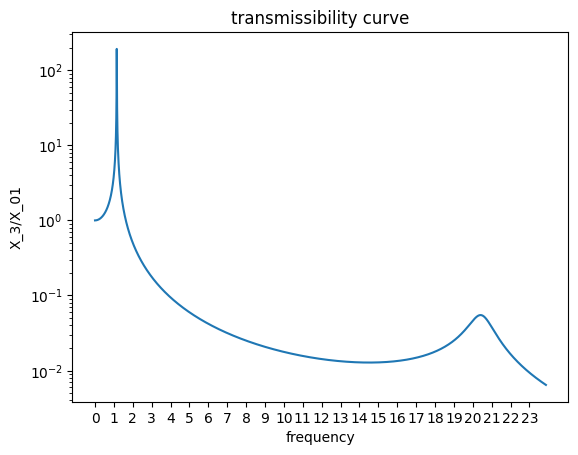



biggest peak at frequency = 1.1509204226389311 Hz

frequency at which the isolation domain starts: 1.6332563673963254 Hz


In [193]:
### Add your code here

#plt.plot(f, np.abs(X3_X01))    #normal axis
plt.semilogy(f, np.abs(X3_X01)) #logarithmic y-axis
plt.xticks(np.arange(0, 150//(2*np.pi)+1, 1))
plt.title("transmissibility curve")
plt.xlabel("frequency")
plt.ylabel("X_3/X_01")

#plt.ylim(0,1)    #if we limit the y-axis to a very small number, we can see a second (small) peak at 20.47Hz

plt.show()

#print the frequency value of the first peak
idx = np.argmax(np.abs(X3_X01))
f_peak = f[idx]
print(f"\n\nbiggest peak at frequency = {f_peak} Hz")

#print the frequency value  for which the amplification = 1
f_amplification1 = f[np.abs(X3_X01)<1]    #gives the frequencies for which the amplification is smaller than 1
isolation_freq = np.min(f_amplification1[f_amplification1>f_peak])
print(f"\nfrequency at which the isolation domain starts: {isolation_freq} Hz")

--> my answer:
*Since X01=X02, we expect two peaks on the transmissibility curve, one at Wn=7,24rad/s (f=1,15Hz) and another one at Wn=128,59 (f=20,47). The reason for this is that when we look back at the modeshapes for certain frequencies, mode 1 and mode 3 would be excited because both wheels move up at the same time(because of displacement X01=X02)*

*When we look at the graph, we see a peak at f=1,15Hz, this peak was expected. The second peak is visible at 20,47Hz as well, but has a very low amplitude (10^-1), the reason for this is that when we look at modeshape 3, mass 1 and 2 move significantly more than mass 3 and since we calculate the response of mass 3 over a range of frequencies (X3/X01 over f:0-23.8), the second peak will be significantly smaller than the first one.*

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

3. Now, use the simplified force vector derived in point 1.2, compute and represent the transmissibility $X_{3}/X_{01}$ using the full model with the coupled equations. Compare with the previous case by plotting the two curves on the same graph and comment. Is the simplification used for the force vector valid in your opinion?

</div>


In [194]:
### Add your code here

#we want to find:   X3/X01 = 3rd row of H * [k,k,0,0]

F_X01_simplified = np.array([k,k,0,0])   #F/X_01 --> force vector without the term X_01

X3_X01_simplified = 0
for j in range(4):
  H_3j_simplified = frequency_response_function(M_mat, C_mat, K_mat, f, i=2, j=j)
  X3_X01_simplified += H_3j_simplified * F_X01_simplified[j]

#print(np.size(X3_X01_simplified))
#print(X3_X01_simplified)

'\nplt.plot(f, np.abs(X3_X01), label="X3/X01")\nplt.plot(f, np.abs(X3_X01_simplified), label="X3/X01 - simplified")\n\nplt.xticks(np.arange(0, 150//(2*np.pi)+1, 1))\nplt.title("transmissibility curve")\nplt.xlabel("frequency")\nplt.ylabel("X_3/X_01")\n\n#plt.ylim(0,1)    #if we limit the y-axis to a very small number, we can see a second (small) peak at 20.47Hz\nplt.legend()\nplt.show()\n'

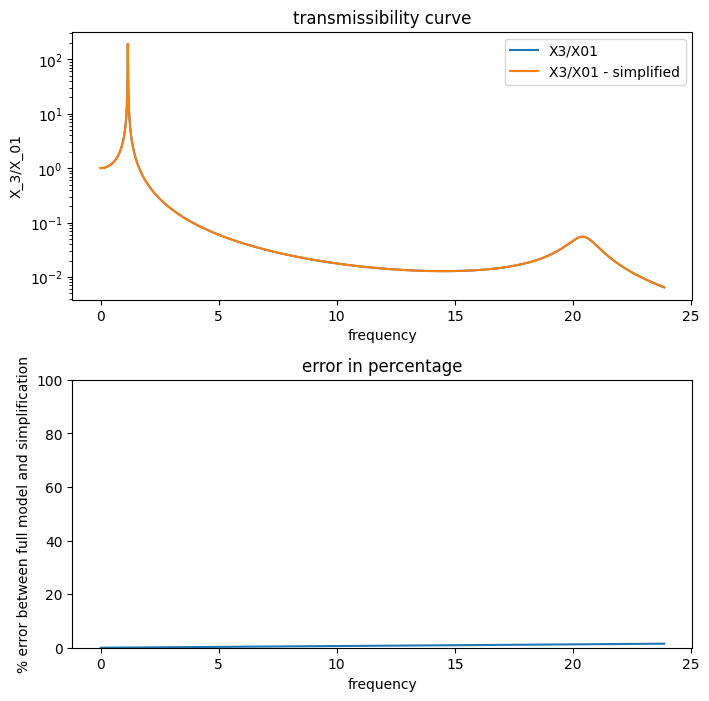

In [195]:
### Add your code here
fig, axes = plt.subplots(2,1, figsize=(8,8))
fig.subplots_adjust(hspace=0.3)
#fig.tight_layout()    #otherwise the plots were too close to eachtoher

#axes[0].plot(f, np.abs(X3_X01), label="X3/X01")                               #normal axis
#axes[0].plot(f, np.abs(X3_X01_simplified), label="X3/X01 - simplified")
axes[0].semilogy(f, np.abs(X3_X01), label="X3/X01")                               #logarithmic axis
axes[0].semilogy(f, np.abs(X3_X01_simplified), label="X3/X01 - simplified")
axes[0].set_title("transmissibility curve")
axes[0].set_xlabel("frequency")
axes[0].set_ylabel("X_3/X_01")
axes[0].legend()

axes[1].plot(f, np.abs(X3_X01 - X3_X01_simplified)/np.abs(X3_X01)*100)
axes[1].set_title("error in percentage")
axes[1].set_ylabel("% error between full model and simplification")
axes[1].set_xlabel("frequency")
axes[1].set_ylim(0,100)


"""
plt.plot(f, np.abs(X3_X01), label="X3/X01")
plt.plot(f, np.abs(X3_X01_simplified), label="X3/X01 - simplified")

plt.xticks(np.arange(0, 150//(2*np.pi)+1, 1))
plt.title("transmissibility curve")
plt.xlabel("frequency")
plt.ylabel("X_3/X_01")

#plt.ylim(0,1)    #if we limit the y-axis to a very small number, we can see a second (small) peak at 20.47Hz
plt.legend()
plt.show()
"""

--> my answer:

*the 2 curves are basically the same, therefore the simplification is valid*

*if we look at the error, we see that it stays well below 5%*

*the reason that these curves are nearly the same is because the only difference between them is the term j.W.b at the force vector, Wmax = 24Hz and b = 10N/(m/s), whilst k = 100000N/m, therefore jWb+k =~ k*

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

4. Assuming $X_{01} = −X_{02}$ , compute and represent the transmissibility $q_{3}/X_{01}$ using the full model with the coupled equations (no simplification of the force vector). Identify to which mode shapes and resonance frequencies the peaks in the transmissibility curve belong. Which kind of imposed motion is applied when $X_{01} = −X_{02}$ ? Can you make a link with the peaks present in the transmissibility curve?

</div>


In [196]:
### Add your code here

#we want to find:   Q3/X01 = 4th row of H * [[jWb+k],[jWb+k],0,0]
f = np.linspace(0, 150/(2*np.pi), 5000)   #from zero to a pulsation of 150rad/s (because natural frequecies range from 7,24 to 128,59) --> convert to frequencies: divide by 2pi

F_X01 = np.array([1j * 2*np.pi*f * b + k, -(1j * 2*np.pi*f * b + k), np.zeros_like(f), np.zeros_like(f)])   #F/X_01 --> force vector without the term X_01; for X01=-X02

Q3_X01 = 0
for j in range(4):
  H_4j = frequency_response_function(M_mat, C_mat, K_mat, f, i=3, j=j)
  Q3_X01 += H_4j * F_X01[j]
#print(f"Q3_X01: \n{Q3_X01}")

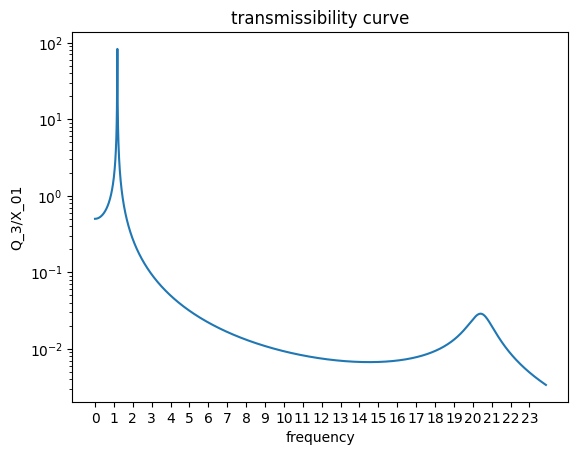



biggest peak at frequency = 1.184349646533008 Hz

frequency at which the isolation domain starts: 1.4517834376856227 Hz


In [197]:
### Add your code here

#plt.plot(f, np.abs(Q3_X01))                           #normal axis
plt.semilogy(f, np.abs(Q3_X01))                       #logarithmic axis
plt.xticks(np.arange(0, 150//(2*np.pi)+1, 1))
plt.title("transmissibility curve")
plt.xlabel("frequency")
plt.ylabel("Q_3/X_01")

#plt.ylim(0,1)    #if we limit the y-axis to a very small number, we can see a second (small) peak at 20.47Hz

plt.show()

#print the frequency value of the first peak
idx = np.argmax(np.abs(Q3_X01))
f_peak = f[idx]
print(f"\n\nbiggest peak at frequency = {f_peak} Hz")

#print the frequency value  for which the amplification = 1
f_amplification1 = f[np.abs(Q3_X01)<1]    #gives the frequencies for which the amplification is smaller than 1
isolation_freq = np.min(f_amplification1[f_amplification1>f_peak])
print(f"\nfrequency at which the isolation domain starts: {isolation_freq} Hz")

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

5. Use the simplified force vector derived in point 1.2, compute and represent the transmissibility $q_{3}/X_{01}$ using the full model with the coupled equations. Compare with the previous case by plotting the two curves on the same graph and comment. Is the simplification used for the force vector valid in your opinion?

</div>


In [198]:
### Add your code here

#we want to find:   Q3/X01 = 4th row of H * [[jWb+k],[jWb+k],0,0]
f = np.linspace(0, 150/(2*np.pi), 5000)   #from zero to a pulsation of 150rad/s (because natural frequecies range from 7,24 to 128,59) --> convert to frequencies: divide by 2pi

F_X01_simplified = np.array([k, -k, 0, 0])   #F/X_01 --> force vector without the term X_01; for X01=-X02

Q3_X01_simplified = 0
for j in range(4):
  H_4j_simplified = frequency_response_function(M_mat, C_mat, K_mat, f, i=3, j=j)
  Q3_X01_simplified += H_4j_simplified * F_X01_simplified[j]
#print(f"Q3_X01_simplified: \n{Q3_X01_simplified}")

'\nplt.plot(f, np.abs(Q3_X01), label="Q3/X01")\nplt.plot(f, np.abs(Q3_X01_simplified), label="Q3/X01 - simplified")\n\nplt.xticks(np.arange(0, 150//(2*np.pi)+1, 1))\nplt.title("transmissibility curve")\nplt.xlabel("frequency")\nplt.ylabel("Q_3/X_01")\n\n#plt.ylim(0,1)    #if we limit the y-axis to a very small number, we can see a second (small) peak at 20.47Hz\nplt.legend()\nplt.show()\n'

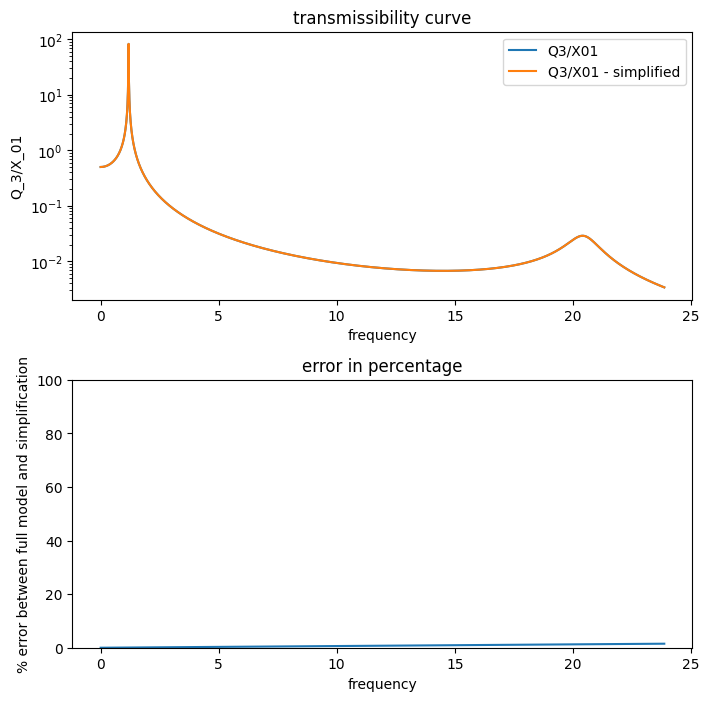

In [199]:
### Add your code here

fig, axes = plt.subplots(2,1, figsize=(8,8))
fig.subplots_adjust(hspace=0.3)
#fig.tight_layout()    #otherwise the plots were too close to eachtoher

#axes[0].plot(f, np.abs(Q3_X01), label="Q3/X01")                             #normal axis
#axes[0].plot(f, np.abs(Q3_X01_simplified), label="Q3/X01 - simplified")
axes[0].semilogy(f, np.abs(Q3_X01), label="Q3/X01")                             #logarithmic axis
axes[0].semilogy(f, np.abs(Q3_X01_simplified), label="Q3/X01 - simplified")
axes[0].set_title("transmissibility curve")
axes[0].set_xlabel("frequency")
axes[0].set_ylabel("Q_3/X_01")
axes[0].legend()

axes[1].plot(f, np.abs(Q3_X01 - Q3_X01_simplified)/np.abs(Q3_X01)*100)
axes[1].set_title("error in percentage")
axes[1].set_ylabel("% error between full model and simplification")
axes[1].set_xlabel("frequency")
axes[1].set_ylim(0,100)


"""
plt.plot(f, np.abs(Q3_X01), label="Q3/X01")
plt.plot(f, np.abs(Q3_X01_simplified), label="Q3/X01 - simplified")

plt.xticks(np.arange(0, 150//(2*np.pi)+1, 1))
plt.title("transmissibility curve")
plt.xlabel("frequency")
plt.ylabel("Q_3/X_01")

#plt.ylim(0,1)    #if we limit the y-axis to a very small number, we can see a second (small) peak at 20.47Hz
plt.legend()
plt.show()
"""

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

6. The transmissibilities are used in the theory of vibration isolation. Comment on the shape of these and make a link with the theory in the course. In your opinion, which frequency bands correspond to the amplification and the isolation domain? What role do the wheels play in the isolation?

</div>


**### Explanation**

The idea here is to isolate the car chassis from the vibrations due to the driving of the car (for example vibrations due to holes in the road). This idea corresponds to the idea of inverse vibration isolation. For the transmissibility we look at the movement (translation or rotation) of the car chassis due to the movement of the wheels on the ground.

We want to decouple the motion of the car chassis from the motion of the wheels.
To reduce the the force transmitted to the car chassis, the frequency of the force should be in the isolation domain, in order to have the isolation domain at a lower frequency, the stiffness of the suspension should be softer BUT it still has to be stiff enough to be able to hold the weight of the car, therefore the stiffness has to be chosen well.

The damping has an influence on the isolation domain as well, although it has almost no influence on the frequency at which the isolation domain starts, it strongly influences the amount of isolation as the frequencies increase. Generally it is better to have low damping because in that case the isolation at high frequencies is better, however there is a trade-off because low damping also means that there is a high amplification at resonance, which is something that should be avoided.
When we look at the values of the damping, we see that they are very low (B0=65 and b=10 for K0=65000 and k=100000)


For the assumption X01=X02, the isolation domain is the domain where the frequency is higher than 1,63Hz (exercise 2.1.2), the amplification domain is the domain where the frequency is lower than 1,63Hz.
For the assumption X01=-X02, the isolation domain starts at a frequency of 1,45Hz (exercise 2.1.4).


The wheels form a second system between the road and the car chassis, in this way the road vibrations aren't transmitted directly to the chassis. The wheels have a mass much smaller than the mass of the car chassis and the tires have a high stiffness, therefore the modeshapes where the wheels vibrate while the chassis barely moves, occur at a high frequency (3rd and 4th modeshape). This can be linked to the modeshapes we discussed earlier: for the modeshapes at f=20,47Hz, the wheels vibrate strongly at this frequency while the chassis barely moves.

## **2.2 Projection in the modal basis**


<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

1. Using the simplified force vector, project the equations of motion in the modal domain. Are the equations uncoupled? Why?

</div>


In [ ]:
### Add your code here

In [ ]:
### Add your code here

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

2. If they are coupled, propose a simplification to decouple the equations of motion, and check its validity by comparing the transmissibility curves $X_{3}/X_{01}$ (assume $X_{01} = X_{02}$ as above), and $q_{3}/X_{01}$ (assume $X_{01} = −X_{02}$ as above) obtained with the full model, and with the decoupled modal projection approach. Is your assumption valid?

</div>


In [ ]:
### Add your code here

In [ ]:
### Add your code here

# **3. Time Domain Computations**

Assume now a given road profile $w$ and $X_{01} \neq X_{02}$. Using the equations with ***absolute coordinates***, and using the simplified force vector used above:


<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

1. Knowing that the frequency of excitation depends on the velocity of the car $v$ and the road profile (in particular the amplitude of its different wavelengths) and using a Fourier transform of the road profile, plot the frequency content of the excitation for three different speeds of the car ($v=5 m/s$, $v= 10 m/s$ and $v=30m/s$).

*N.B.: The road profile is defined in the **w.csv** file (first column: spatial coordinate, second column: road profile amplitude)*

</div>


In [ ]:
### Add your code here

In [ ]:
### Add your code here

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

2. Compute and represent the absolute displacement $X_{3}(t)$ for the three car speeds. Use a convolution between the force vector and the impulse responses, and work with the uncoupled equations in the modal basis. (hint: consider $X_{01}$ and $X_{02}$ as two independent excitation sources, and sum the responses using the property of linearity of the system). Use a relative time ($t/tmax$) in order to plot the curves on the same graph and compare.

*Hint: Use the function `convolve` from `scipy.signal` to compute the convolution as it is faster that numpy*

*Hint: When convolving the force vector with the impulse response, make sure to multiply the result by the time step to get the correct result*
</div>


In [ ]:
### Add your code here

In [ ]:
### Add your code here

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

3. Represent the frequency content of the three time domain signals obtained. Compare it to the frequency content of the excitation and comment. What differences do you see for the three different velocities and why ?

</div>

In [ ]:
### Add your code here

In [ ]:
### Add your code here

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

4. Do you notice a difference in the time domain responses in terms of amplitude? Why? Can you make a link with the transmissibility curves computed previously? Can you make a link with the theory covered in the chapter about vibration isolation? At which speed(s) is the car body best isolated?

</div>


### Add your explanation here

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

5. Repeat points (2) to (4) for $q_{3}(t)$ at the three different speeds.

</div>


In [ ]:
### Add your code here

In [ ]:
### Add your code here